#Optimisation des Hyperparamètres (Grid Search & Évaluation Finale)

## Contexte et Objectifs
Après avoir identifié la **Régression Logistique** comme le modèle le plus prometteur lors du benchmark, nous procédons à une optimisation systématique de ses hyperparamètres par **GridSearchCV** afin d'obtenir la configuration optimale pour le déploiement.

### Hyperparamètres explorés :
- `model__C` : Paramètre de régularisation inverse `[0.01, 0.1, 1, 10, 100]`.
- `model__penalty` : Type de pénalité `['l1', 'l2']` pour sélectionner les variables ou lisser les poids.
- `model__solver` : Solveur `['saga']` compatible avec la pénalité L1 et la classification multinomiale.
- `model__class_weight` : Prise en compte éventuelle du déséquilibre des classes `[None, 'balanced']`.


## 1. Importations et Préparation
Chargement des fonctions du module `src.tune` et des données brutes.


In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Importer les fonctions
from src.tune import (
    
        search_params,
        evaluate_final_model
       
   
)
data_path = PROJECT_ROOT / "data" / "raw" / "student_mental_health.csv"
df=pd.read_csv(data_path)  


## 2. Optimisation par GridSearchCV et Évaluation Détaillée
Exécution de `search_params(df)` et `evaluate_final_model(df)` :
- Recherche exhaustive par validation croisée à 5 plis.
- Extraction des meilleurs paramètres et du meilleur estimateur.
- Évaluation sur l'ensemble de test : Rapport complet de classification (Précision, Rappel, F1-score) et Matrice de Confusion finale.


Fitting 5 folds for each of 20 candidates, totalling 100 fits


/home/kawkaw/Croise/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/kawkaw/Croise/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/kawkaw/Croise/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 

Best accurcy macro: 0.758125
Best Parameters: {'model__C': 10, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'model__solver': 'saga'}
Classification Report:
              precision    recall  f1-score   support

         Low       0.83      0.79      0.81       132
      Medium       0.65      0.67      0.66       132
        High       0.84      0.85      0.84       136

    accuracy                           0.77       400
   macro avg       0.77      0.77      0.77       400
weighted avg       0.77      0.77      0.77       400



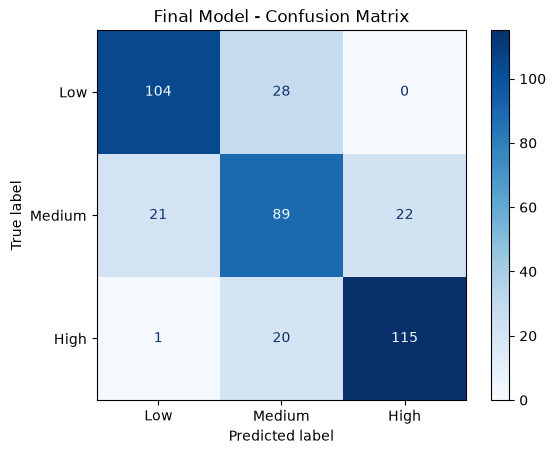

Modèle sauvegardé avec succès dans models/model.joblib


In [2]:
# Optimisation des hyperparamètres et évaluation finale
best_model, y_pred = evaluate_final_model(df)




## 3. Conclusion & Validation du Modèle Final

### Synthèse des Performances :
- **Meilleurs hyperparamètres** : Régularisation $C=10$, pénalité `l1`, solveur `saga`, et pondération `balanced`.
- **Performance finale sur Test** :
  - **Accuracy globale** : **~77%**.
  - **Précision / Rappel** : Équilibrés à plus de 80% sur les classes `Low` et `High`.
- **État de préparation** : Le pipeline optimisé est validé et prêt à être sérialisé (`joblib.dump`) pour alimenter le pipeline automatisé **Apache Airflow** (DAG) et l'interface applicative **Streamlit**.
